# CP0

In [1]:
import ee
ee.Authenticate()
ee.Initialize(project='earth-engine-uhi')  # Pune ID-ul exact copiat la Pasul 2

print("Conexiunea la Earth Engine funcționează perfect!")

Conexiunea la Earth Engine funcționează perfect!


## Verificari si observatii asupra datelor folosite

In [2]:
import ee

# 1. Definim punctul central (București) și un buffer de analiză
bucuresti_center = ee.Geometry.Point([26.1025, 44.4268])

# 2. Interogăm colecția Landsat 8/9 Level-2 (Termic - LST)
# Filtrăm: Iunie - August 2023, nori sub 20%
landsat_summer = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                  .filterBounds(bucuresti_center)
                  .filterDate('2026-06-01', '2026-08-31')
                  .filter(ee.Filter.lt('CLOUD_COVER', 20)))

# 3. Interogăm colecția Sentinel-2 Level-2A (Optic - NDVI/NDBI)
# Același interval temporal
sentinel_summer = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                   .filterBounds(bucuresti_center)
                   .filterDate('2023-06-01', '2023-08-31')
                   .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))

# Extragem metadatele ca dovadă de acces
l8_dates = landsat_summer.aggregate_array('DATE_ACQUIRED').getInfo()
l8_count = landsat_summer.size().getInfo()
s2_count = sentinel_summer.size().getInfo()

print("=" * 60)
print(f"DOVADĂ ACCESARE SURSA 1 (Landsat 8 - LST):")
print(f"  • Număr scene senine identificate: {l8_count}")
print(f"  • Datele de achiziție: {l8_dates}")
print("=" * 60)
print(f"DOVADĂ ACCESARE SURSA 1 (Sentinel-2 - Optic):")
print(f"  • Număr scene senine identificate: {s2_count}")
print("=" * 60)

DOVADĂ ACCESARE SURSA 1 (Landsat 8 - LST):
  • Număr scene senine identificate: 7
  • Datele de achiziție: ['2026-06-14', '2026-06-30', '2026-08-01', '2026-08-17', '2026-06-21', '2026-07-07', '2026-08-08']
DOVADĂ ACCESARE SURSA 1 (Sentinel-2 - Optic):
  • Număr scene senine identificate: 13


In [3]:
import ee
import pandas as pd

# 1. Punct central București
bucuresti_center = ee.Geometry.Point([26.1025, 44.4268])

# 2. Colecții filtrate (Vara 2023)
landsat_summer = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                  .filterBounds(bucuresti_center)
                  .filterDate('2023-06-01', '2023-08-31')
                  .filter(ee.Filter.lt('CLOUD_COVER', 20)))

sentinel_summer = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                   .filterBounds(bucuresti_center)
                   .filterDate('2023-06-01', '2023-08-31')
                   .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))

# 3. Funcții helper pentru extragerea proprietăților tabulare
def get_landsat_metadata(img):
    return ee.Feature(None, {
        'Satelit': 'Landsat 8 (TIRS/OLI)',
        'Tip_Date': 'Termic (LST) & Refl.',
        'Data_Achizitie': img.get('DATE_ACQUIRED'),
        'Acoperire_Nori_%': ee.Number(img.get('CLOUD_COVER')).round(),
        'Scene_ID': img.get('system:index')
    })

def get_sentinel_metadata(img):
    # Sentinel stochează data în timestamp milisecunde
    date_str = ee.Date(img.get('system:time_start')).format('YYYY-MM-dd')
    return ee.Feature(None, {
        'Satelit': 'Sentinel-2 (MSI)',
        'Tip_Date': 'Optic (NDVI / NDBI)',
        'Data_Achizitie': date_str,
        'Acoperire_Nori_%': ee.Number(img.get('CLOUDY_PIXEL_PERCENTAGE')).round(),
        'Scene_ID': img.get('system:index')
    })

# 4. Mapare și extragere în Python
l8_features = landsat_summer.map(get_landsat_metadata).getInfo()['features']
s2_features = sentinel_summer.map(get_sentinel_metadata).getInfo()['features']

# 5. Construire DataFrame
rows = [f['properties'] for f in l8_features] + [f['properties'] for f in s2_features]
df_scene = pd.DataFrame(rows)

# Sortare cronologică
df_scene['Data_Achizitie'] = pd.to_datetime(df_scene['Data_Achizitie'])
df_scene = df_scene.sort_values(by=['Data_Achizitie', 'Satelit']).reset_index(drop=True)

# Reordonare coloane
df_scene = df_scene[['Data_Achizitie', 'Satelit', 'Tip_Date', 'Acoperire_Nori_%', 'Scene_ID']]

# Afișare tabel formatat în notebook
display(df_scene)

,Data_Achizitie,Satelit,Tip_Date,Acoperire_Nori_%,Scene_ID
0,2023-06-06,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,7,LC08_182029_20230606
1,2023-06-22,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,9,LC08_182029_20230622
2,2023-06-24,Sentinel-2 (MSI),Optic (NDVI / NDBI),1,20230624T090601_20230624T091055_T35TMK
3,2023-06-29,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,13,LC08_183029_20230629
4,2023-06-29,Sentinel-2 (MSI),Optic (NDVI / NDBI),9,20230629T090559_20230629T091459_T35TMK
5,2023-07-04,Sentinel-2 (MSI),Optic (NDVI / NDBI),12,20230704T090601_20230704T091054_T35TMK
6,2023-07-09,Sentinel-2 (MSI),Optic (NDVI / NDBI),4,20230709T090559_20230709T091057_T35TMK
7,2023-07-14,Sentinel-2 (MSI),Optic (NDVI / NDBI),0,20230714T090601_20230714T091057_T35TMK
8,2023-07-15,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,15,LC08_183029_20230715
9,2023-07-19,Sentinel-2 (MSI),Optic (NDVI / NDBI),17,20230719T090559_20230719T091058_T35TMK


In [4]:
import ee

ee.Initialize(project='earth-engine-uhi')

# 1. Punct de control: Piața Universității, București
point_sample = ee.Geometry.Point([26.1025, 44.4355])

# 2. Sursa 3: WorldPop 100m (Populație)
worldpop = (ee.ImageCollection('WorldPop/GP/100m/pop')
            .filterBounds(point_sample)
            .filter(ee.Filter.eq('year', 2020))
            .first())

pop_val = worldpop.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=point_sample,
    scale=100
).getInfo()

# 3. Sursa 2b: GHSL Built-Up Grid (Copernicus JRC Built Surface Presence)
ghsl_built = ee.Image('JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1')

built_val = ghsl_built.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=point_sample,
    scale=100
).getInfo()

print("=" * 60)
print("DOVADĂ ACCESARE SURSA 3 (WorldPop 100m - Populație):")
print(f"  • Asset ID: WorldPop/GP/100m/pop (anul 2020)")
print(f"  • Estimare populație per celulă 100m: {pop_val.get('population'):.1f} locuitori")
print("=" * 60)
print("DOVADĂ ACCESARE SURSA 2b (GHSL Urban Built-Up):")
print(f"  • Asset ID: JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1")
print(f"  • Valoare grid construit (epoch classification): {built_val}")
print("=" * 60)

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for WorldPop/GP/100m/pop! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by WorldPop/GP/100m/R2025A/v1/pop

Learn more: https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop

  warnings.warn(warning, category=DeprecationWarning)


DOVADĂ ACCESARE SURSA 3 (WorldPop 100m - Populație):
  • Asset ID: WorldPop/GP/100m/pop (anul 2020)
  • Estimare populație per celulă 100m: 101.5 locuitori
DOVADĂ ACCESARE SURSA 2b (GHSL Urban Built-Up):
  • Asset ID: JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1
  • Valoare grid construit (epoch classification): {'built': 6, 'cnfd': 236, 'dm': 16}


/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by JRC/GHSL/P2023A/GHS_BUILT_S

Learn more: https://developers.google.com/earth-engine/datasets/catalog/JRC_GHSL_P2016_BUILT_LDSMT_GLOBE_V1

  warnings.warn(warning, category=DeprecationWarning)


# CP1

# Data Card

In [5]:
import ee

ee.Initialize(project='earth-engine-uhi')

def inspect_gee_asset(asset_id: str, is_collection: bool = False):
    if is_collection:
        img = ee.ImageCollection(asset_id).first()
    else:
        img = ee.Image(asset_id)
        
    info = img.getInfo()
    bands = [b['id'] for b in info.get('bands', [])]
    
    # Selectăm prima bandă și îi extragem proiecția
    first_band = img.select(0)
    proj = first_band.projection()
    
    # Metoda corectă în EE Python API este nominalScale()
    nominal_scale = proj.nominalScale().getInfo()
    crs = proj.crs().getInfo()
    
    print(f"Dataset: {asset_id}")
    print(f"  • Număr total benzi: {len(bands)}")
    print(f"  • Primele benzi: {bands[:6]}")
    print(f"  • Rezoluție nominală: ~{round(nominal_scale, 2)} m")
    print(f"  • CRS nativ: {crs}")
    print("-" * 60)

# Verificare pentru sursele din proiect:
inspect_gee_asset('LANDSAT/LC08/C02/T1_L2', is_collection=True)
inspect_gee_asset('COPERNICUS/S2_SR_HARMONIZED', is_collection=True)
inspect_gee_asset('WorldPop/GP/100m/pop', is_collection=True)

Dataset: LANDSAT/LC08/C02/T1_L2
  • Număr total benzi: 19
  • Primele benzi: ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6']
  • Rezoluție nominală: ~30 m
  • CRS nativ: EPSG:32628
------------------------------------------------------------
Dataset: COPERNICUS/S2_SR_HARMONIZED
  • Număr total benzi: 26
  • Primele benzi: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6']
  • Rezoluție nominală: ~60 m
  • CRS nativ: EPSG:32633
------------------------------------------------------------
Dataset: WorldPop/GP/100m/pop
  • Număr total benzi: 1
  • Primele benzi: ['population']
  • Rezoluție nominală: ~92.77 m
  • CRS nativ: EPSG:4326
------------------------------------------------------------


In [6]:
!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 1.8 MB/s eta 0:00:0000:01


In [7]:
# import osmnx as ox
# import geopandas as gpd
# import pandas as pd

# # ==========================================
# # 1. Inspectare date OpenStreetMap (OSM)
# # ==========================================
# print("Interogare OpenStreetMap pentru eșantionul București...")
# coords = (44.4355, 26.1025) # Centru București

# # Descarcă amprente clădiri pe un eșantion de 500m
# gdf_buildings = ox.features_from_point(coords, tags={'building': True}, dist=500)

# # Păstrăm doar poligoanele valide
# gdf_buildings = gdf_buildings[gdf_buildings.geometry.type.isin(['Polygon', 'MultiPolygon'])]

# # Calculăm statistici descriptive specifice OSM
# # Proiectăm temporar în Stereo 70 (EPSG:3844) pentru calcule metrice reale
# gdf_proj = gdf_buildings.to_crs(epsg=3844)
# areas = gdf_proj.geometry.area

# print("=" * 60)
# print("METADATE OPENSTREETMAP (OSM) - Clădiri (Vectorial):")
# print(f"  • Tip geometrie: {gdf_buildings.geometry.type.unique()}")
# print(f"  • Număr obiecte în eșantion: {len(gdf_buildings)}")
# print(f"  • CRS descărcat nativ: {gdf_buildings.crs}")
# print(f"  • Aria medie a unei clădiri: {areas.mean():.1f} m² (Min: {areas.min():.1f} m², Max: {areas.max():.1f} m²)")
# print(f"  • Coloane/Atribute principale OSM disponibile:")
# for col in ['building', 'building:levels', 'height', 'addr:street']:
#     if col in gdf_buildings.columns:
#         valid_cnt = gdf_buildings[col].dropna().count()
#         print(f"     - {col}: {valid_cnt} valori nenule ({round(valid_cnt/len(gdf_buildings)*100, 1)}%)")
# print("=" * 60)

In [8]:
import ee

ee.Initialize(project='earth-engine-uhi')

# Copernicus GHSL Built-Up Grid
ghsl_asset_id = 'JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1'
ghsl_img = ee.Image(ghsl_asset_id)

# Lista tuturor benzilor disponibile
bands = ghsl_img.bandNames().getInfo()

# Selectăm explicit prima bandă pentru a interoga proiecția și rezoluția
first_band = ghsl_img.select(0)
proj = first_band.projection()
scale = proj.nominalScale().getInfo()
crs = proj.crs().getInfo()

print("=" * 60)
print("METADATE COPERNICUS GHSL (Fond Construit):")
print(f"  • Asset ID: {ghsl_asset_id}")
print(f"  • Benzi: {bands}")
print(f"  • Rezoluție nominală: ~{round(scale, 1)} metri")
print(f"  • Sistem de coordonate: {crs}")
print("=" * 60)

METADATE COPERNICUS GHSL (Fond Construit):
  • Asset ID: JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1
  • Benzi: ['built', 'cnfd', 'dm']
  • Rezoluție nominală: ~38.2 metri
  • Sistem de coordonate: EPSG:3857


# Colectarea datelor

In [9]:
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon, Point

# 1. Bounding box general București (WGS84)
bbox_wgs84 = (25.96, 44.33, 26.24, 44.55)

# 2. Conversie în Stereo 70 (EPSG:3844) pentru coordonate metrice reale
gdf_bbox = gpd.GeoDataFrame(
    geometry=[Polygon.from_bounds(*bbox_wgs84)], 
    crs="EPSG:4326"
).to_crs("EPSG:3844")

minx, miny, maxx, maxy = gdf_bbox.total_bounds
cell_size = 250  # 250 metri

x_coords = np.arange(minx, maxx, cell_size)
y_coords = np.arange(miny, maxy, cell_size)

polygons = []
cell_ids = []
idx = 0

for x in x_coords:
    for y in y_coords:
        poly = Polygon([
            (x, y),
            (x + cell_size, y),
            (x + cell_size, y + cell_size),
            (x, y + cell_size)
        ])
        polygons.append(poly)
        cell_ids.append(f"cell_{idx:05d}")
        idx += 1

gdf_grid = gpd.GeoDataFrame({
    'cell_id': cell_ids,
    'geometry': polygons
}, crs="EPSG:3844")

# 3. Delimitarea celor două zone de comparație (Exemplu: Centru vs Periferie sau Nord vs Sud)
# Definim centrul istoric / Piața Universității în Stereo 70
punct_centru_wgs84 = gpd.GeoDataFrame(
    geometry=[Point(26.1025, 44.4355)], crs="EPSG:4326"
).to_crs("EPSG:3844").geometry.iloc[0]

# Calculăm distanța fiecărui centroid de celulă până la centru
distante_centru = gdf_grid.geometry.centroid.distance(punct_centru_wgs84)

# ZONA A: Nucleu Urban Central (buffer < 4.5 km - densitate maximă, clădiri compacte)
# ZONA B: Coridor Periurban / Exterior (distanță > 4.5 km - mixt rezidențial, industrial, spații deschise)
gdf_grid['zone_label'] = np.where(distante_centru <= 4500, 'Nucleu_Urban_Central', 'Periferie_Periurban')

# Alternativă simplă: Împărțire Nord vs Sud folosind mediana axei Y
# y_mid = (miny + maxy) / 2
# gdf_grid['zone_label'] = np.where(gdf_grid.geometry.centroid.y >= y_mid, 'Bucuresti_Nord', 'Bucuresti_Sud')

# Versiunea în WGS84 necesară pentru interogarea Google Earth Engine
gdf_grid_wgs84 = gdf_grid.to_crs("EPSG:4326")

print("Distribuția celulelor pe cele două zone de comparație:")
print(gdf_grid['zone_label'].value_counts())

Distribuția celulelor pe cele două zone de comparație:
zone_label
Periferie_Periurban     7994
Nucleu_Urban_Central    1015
Name: count, dtype: int64


In [10]:
import ee
import pandas as pd
import json

ee.Initialize(project='earth-engine-uhi')

# 1. Definim compozitul sezonier de vară 2025 (Iun - Aug)
start_date = '2025-06-01'
end_date = '2025-09-01'
aoi = ee.Geometry.BBox(*bbox_wgs84)

# --- A. Landsat 8/9 -> LST (°C) ---
def prep_landsat_lst(img):
    lst_c = img.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15).rename('lst_celsius')
    qa = img.select('QA_PIXEL')
    mask = qa.bitwiseAnd(1 << 4).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0)) # fără nori/umbre
    return lst_c.updateMask(mask)

landsat_comp = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                .filterBounds(aoi)
                .filterDate(start_date, end_date)
                .filter(ee.Filter.lt('CLOUD_COVER', 30))
                .map(prep_landsat_lst)
                .median())

# --- B. Sentinel-2 -> NDVI & NDBI ---
def prep_sentinel_indices(img):
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('ndvi')
    ndbi = img.normalizedDifference(['B11', 'B8']).rename('ndbi')
    scl = img.select('SCL')
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)) # fără nori
    return ndvi.addBands(ndbi).updateMask(mask)

sentinel_comp = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                 .filterBounds(aoi)
                 .filterDate(start_date, end_date)
                 .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 25))
                 .map(prep_sentinel_indices)
                 .median())

# --- C. WorldPop 100m -> Populație ---
worldpop = (ee.ImageCollection('WorldPop/GP/100m/R2025A/v1/pop')
            .filterBounds(aoi)
            .filter(ee.Filter.eq('country', 'ROU'))
            .filter(ee.Filter.eq('year', 2025))
            .first()
            .select('population')
            .rename('population_count'))

# Imaginea unificată cu toate cele 4 variabile raster
composite_all = landsat_comp.addBands(sentinel_comp).addBands(worldpop)


# 2. Extracție pe loturi (batch-uri de 500 celule pentru stabilitate)
batch_size = 500
records = []
total_cells = len(gdf_grid_wgs84)

print(f"Începe extragerea din Earth Engine pentru {total_cells} de celule...")

for i in range(0, total_cells, batch_size):
    batch_gdf = gdf_grid_wgs84.iloc[i : i + batch_size]
    
    # Conversie GeoDataFrame -> ee.FeatureCollection
    geojson_features = json.loads(batch_gdf[['cell_id', 'geometry']].to_json())['features']
    ee_fc = ee.FeatureCollection(geojson_features)
    
    # Reducere zonală prin medie
    reduced = composite_all.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.mean(),
        scale=30
    )
    
    # Colectare rezultate
    feats = reduced.getInfo()['features']
    for f in feats:
        props = f['properties']
        records.append({
            'cell_id': props.get('cell_id'),
            'lst_celsius': props.get('lst_celsius'),
            'ndvi': props.get('ndvi'),
            'ndbi': props.get('ndbi'),
            'population_count': props.get('population_count')
        })
    print(f"Progres: {min(i + batch_size, total_cells)} / {total_cells} celule procesate.")

df_raster = pd.DataFrame(records)
print("Extragere completă din Earth Engine!")
display(df_raster.head())

Începe extragerea din Earth Engine pentru 9009 de celule...
Progres: 500 / 9009 celule procesate.
Progres: 1000 / 9009 celule procesate.
Progres: 1500 / 9009 celule procesate.
Progres: 2000 / 9009 celule procesate.
Progres: 2500 / 9009 celule procesate.
Progres: 3000 / 9009 celule procesate.
Progres: 3500 / 9009 celule procesate.
Progres: 4000 / 9009 celule procesate.
Progres: 4500 / 9009 celule procesate.
Progres: 5000 / 9009 celule procesate.
Progres: 5500 / 9009 celule procesate.
Progres: 6000 / 9009 celule procesate.
Progres: 6500 / 9009 celule procesate.
Progres: 7000 / 9009 celule procesate.
Progres: 7500 / 9009 celule procesate.
Progres: 8000 / 9009 celule procesate.
Progres: 8500 / 9009 celule procesate.
Progres: 9000 / 9009 celule procesate.
Progres: 9009 / 9009 celule procesate.
Extragere completă din Earth Engine!


,cell_id,lst_celsius,ndvi,ndbi,population_count
0,cell_00000,36.164025,0.625023,-0.106708,1.998816
1,cell_00001,38.474571,0.556102,-0.052520,1.502125
2,cell_00002,43.109277,0.416865,0.005692,0.600958
3,cell_00003,46.424002,0.269983,0.074986,0.116983
4,cell_00004,46.108377,0.261622,0.088478,0.739933


In [11]:
# Unim datele extrase din GEE cu grid-ul de bază
gdf_merged = gdf_grid.merge(df_raster, on='cell_id', how='left')

In [12]:
gdf_merged

,cell_id,geometry,zone_label,lst_celsius,ndvi,ndbi,population_count
0,cell_00000,"POLYGON ((576395.486 314923.984, 576645.486 31...",Periferie_Periurban,36.164025,0.625023,-0.106708,1.998816
1,cell_00001,"POLYGON ((576395.486 315173.984, 576645.486 31...",Periferie_Periurban,38.474571,0.556102,-0.052520,1.502125
2,cell_00002,"POLYGON ((576395.486 315423.984, 576645.486 31...",Periferie_Periurban,43.109277,0.416865,0.005692,0.600958
3,cell_00003,"POLYGON ((576395.486 315673.984, 576645.486 31...",Periferie_Periurban,46.424002,0.269983,0.074986,0.116983
4,cell_00004,"POLYGON ((576395.486 315923.984, 576645.486 31...",Periferie_Periurban,46.108377,0.261622,0.088478,0.739933
...,...,...,...,...,...,...,...
9004,cell_09004,"POLYGON ((598895.486 338423.984, 599145.486 33...",Periferie_Periurban,40.619178,0.512038,-0.041609,NaN
9005,cell_09005,"POLYGON ((598895.486 338673.984, 599145.486 33...",Periferie_Periurban,39.932817,0.581342,-0.119151,NaN
9006,cell_09006,"POLYGON ((598895.486 338923.984, 599145.486 33...",Periferie_Periurban,40.559557,0.500898,-0.037473,NaN
9007,cell_09007,"POLYGON ((598895.486 339173.984, 599145.486 33...",Periferie_Periurban,43.269888,0.395397,0.055108,NaN


In [13]:
# import ee
# import json
# import pandas as pd
# import geopandas as gpd

# # 1. Calculăm centroizii corect în CRS metric (Stereo 70) pentru acuratețe, apoi reproiectăm în WGS84
# gdf_centroids = gdf_grid[['cell_id', 'geometry']].copy()
# gdf_centroids['geometry'] = gdf_centroids.geometry.centroid
# gdf_centroids_wgs84 = gdf_centroids.to_crs(epsg=4326)

# # 2. Preluăm stratul GHSL
# ghsl_img = ee.Image(
#     'JRC/GHSL/P2023A/GHS_BUILT_S/2025'
# ).select('built_surface')

# # 3. Eșantionare pe loturi folosind .sampleRegions()
# batch_size = 1500
# records_morpho = []
# total_cells = len(gdf_centroids_wgs84)

# print(f"Eșantionare stabilă GHSL pentru {total_cells} puncte...")

# for i in range(0, total_cells, batch_size):
#     batch_gdf = gdf_centroids_wgs84.iloc[i : i + batch_size]
#     geojson_features = json.loads(batch_gdf.to_json())['features']
#     ee_fc = ee.FeatureCollection(geojson_features)
    
#     # sampleRegions este conceput nativ pentru puncte/centroizi
#     sampled = ghsl_img.sampleRegions(
#         collection=ee_fc,
#         properties=['cell_id'],
#         scale=100,
#         geometries=False
#     )
    
#     feats = sampled.getInfo()['features']
#     for f in feats:
#         props = f['properties']
#         records_morpho.append({
#             'cell_id': props.get('cell_id'),
#             'built_surface': props.get('built', 0)
#         })
#     print(f"Progres: {min(i + batch_size, total_cells)} / {total_cells}")

# df_morpho = pd.DataFrame(records_morpho)

# print("\nStatistici verificate Copernicus GHSL:")
# print(df_morpho['built_surface'].describe())

# 1. Preluăm stratul GHSL pentru 2025
ghsl_img = ee.Image(
    'JRC/GHSL/P2023A/GHS_BUILT_S/2025'  # ESTE CONSTRUIT PE BAZA DE ESTIMARI, nu este masurat prin satelit
).select('built_surface')

# 2. Adăugăm suprafața celulelor (în m²)
gdf_grid_wgs84 = gdf_grid_wgs84.copy()
gdf_grid_wgs84['cell_area_m2'] = gdf_grid.geometry.area.values

# 3. Extracție zonală pe loturi
batch_size = 1500
records_morpho = []
total_cells = len(gdf_grid_wgs84)

print(f"Extragere GHSL pentru {total_cells} celule...")

for i in range(0, total_cells, batch_size):
    batch_gdf = gdf_grid_wgs84.iloc[i : i + batch_size]

    geojson_features = json.loads(
        batch_gdf[['cell_id', 'cell_area_m2', 'geometry']].to_json()
    )['features']

    ee_fc = ee.FeatureCollection(geojson_features)

    # Calculăm suprafața construită totală
    reduced = ghsl_img.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.sum(),
        scale=100
    )

    feats = reduced.getInfo()['features']

    for f in feats:
        props = f['properties']

        built_area = props.get('sum')
        cell_area = props.get('cell_area_m2')

        records_morpho.append({
            'cell_id': props.get('cell_id'),
            'built_surface': built_area,
            'built_percent': (
                built_area / cell_area * 100
                if built_area is not None and cell_area
                else None
            )
        })

    print(f"Progres: {min(i + batch_size, total_cells)} / {total_cells}")

df_morpho = pd.DataFrame(records_morpho)

print("\nStatistici GHSL - procent suprafață construită:")
print(df_morpho['built_percent'].describe())

Extragere GHSL pentru 9009 celule...
Progres: 1500 / 9009
Progres: 3000 / 9009
Progres: 4500 / 9009
Progres: 6000 / 9009
Progres: 7500 / 9009
Progres: 9000 / 9009
Progres: 9009 / 9009

Statistici GHSL - procent suprafață construită:
count    9009.000000
mean       16.856489
std        15.697525
min         0.000000
25%         0.717747
50%        13.616740
75%        31.287115
max        99.495868
Name: built_percent, dtype: float64


In [14]:

import pandas as pd
import geopandas as gpd

# 1. Îmbinăm datele morfologice GHSL cu tabelul principal extras anterior
df_final = gdf_merged.merge(df_morpho, on='cell_id', how='left')

# 2. Imputare logică pentru eventuale valori lipsă
df_final['built_surface'] = df_final['built_surface'].fillna(0.0)
df_final['built_percent'] = df_final['built_percent'].fillna(0.0)
df_final['population_count'] = df_final['population_count'].fillna(0.0)
df_final['time_window'] = '2025_summer'

# 3. Ordonarea standard a coloanelor
cols_final = [
    'cell_id', 'time_window', 'zone_label',
    'lst_celsius', 'ndvi', 'ndbi',
    'built_surface','built_percent', 'population_count',
    'geometry'
]
df_final = df_final[cols_final]

# 4. Eliminarea celulelor fără observații termice valide (mască nori / apă completă)
df_clean = df_final.dropna(subset=['lst_celsius']).copy()

# 5. Export fișiere
csv_filename = "dataset_aligned_bucharest_250m.csv"
gpkg_filename = "dataset_aligned_bucharest_250m.gpkg"

df_clean.drop(columns=['geometry']).to_csv(csv_filename, index=False)
df_clean.to_file(gpkg_filename, driver="GPKG")

print(f"Salvat cu succes: {csv_filename} ({len(df_clean)} rânduri)")
print(f"Salvat cu succes: {gpkg_filename}")

Salvat cu succes: dataset_aligned_bucharest_250m.csv (8567 rânduri)
Salvat cu succes: dataset_aligned_bucharest_250m.gpkg


In [15]:
total_teoretic = len(df_final)
total_valid = len(df_clean)
pierderi = total_teoretic - total_valid
rata_supravietuire = (total_valid / total_teoretic) * 100

print("=" * 65)
print("RAPORT DE ACOPERIRE ȘI SUPRAVIEȚUIRE (ATTRITION REPORT)")
print("=" * 65)
print(f"Unități inițiale generate în grid (250m x 250m):  {total_teoretic}")
print(f"Unități validate după fuziune și filtrare LST:   {total_valid} ({rata_supravietuire:.2f}%)")
print(f"Unități eliminate (mască de nori/apă/margini):     {pierderi} ({100 - rata_supravietuire:.2f}%)")
print("-" * 65)
print("Distribuția unităților pe zone de analiză:")
for zona, cnt in df_clean['zone_label'].value_counts().items():
    print(f"  • {zona}: {cnt} celule ({cnt/total_valid*100:.1f}%)")
print("-" * 65)
print("Sumar statistic variabile (Mediană / Medie / Deviere Standard):")
display(df_clean[['lst_celsius', 'ndvi', 'ndbi', 'built_surface','built_percent', 'population_count']].describe().round(2))
print("=" * 65)

RAPORT DE ACOPERIRE ȘI SUPRAVIEȚUIRE (ATTRITION REPORT)
Unități inițiale generate în grid (250m x 250m):  9009
Unități validate după fuziune și filtrare LST:   8567 (95.09%)
Unități eliminate (mască de nori/apă/margini):     442 (4.91%)
-----------------------------------------------------------------
Distribuția unităților pe zone de analiză:
  • Periferie_Periurban: 7554 celule (88.2%)
  • Nucleu_Urban_Central: 1013 celule (11.8%)
-----------------------------------------------------------------
Sumar statistic variabile (Mediană / Medie / Deviere Standard):


,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count
count,8567.00,8567.00,8567.00,8567.00,8567.00,8567.00
mean,41.32,0.38,-0.04,10499.55,16.80,22.69
std,3.43,0.16,0.10,9821.74,15.71,29.74
min,28.47,-0.26,-0.44,0.00,0.00,0.00
25%,39.84,0.27,-0.10,412.14,0.66,0.54
50%,41.70,0.36,-0.03,8407.82,13.45,7.72
75%,43.48,0.47,0.03,19554.75,31.29,36.72
max,51.08,0.88,0.25,62184.92,99.50,115.52


In [16]:
print("Celule în grila inițială:", len(gdf_grid))
print("Celule în df_final:", len(df_final))
print("Celule fără LST:", df_final['lst_celsius'].isna().sum())
print("Celule în df_clean:", len(df_clean))

Celule în grila inițială: 9009
Celule în df_final: 9009
Celule fără LST: 442
Celule în df_clean: 8567


In [17]:
# # Harta interactivă a Bounding Box-ului peste fundalul real al Bucureștiului
# m = gdf_bbox.explore(
#     color="crimson",
#     style_kwds={"fillColor": "crimson", "fillOpacity": 0.15, "weight": 2.5},
#     name="Bounding Box București"
# )

# # Afișează harta direct în notebook
# m

# Vizualizare grid-uri

In [18]:
# Vizualizare interactivă a gridului colorat pe zone
gdf_grid_wgs84.sample(1500).explore(
    column="zone_label",
    cmap="coolwarm",
    style_kwds={"fillOpacity": 0.4, "weight": 0.5},
    legend=True
)

In [19]:
# Lista coloanelor critice pe care le dorești complete
required_cols = [
    'lst_celsius', 
    'ndvi', 
    'ndbi', 
    'built_surface',
    'built_percent',
    'population_count'
]

# Creează o coloană booleană: True dacă toate coloanele au valori valide, False altfel
df_clean['is_complete'] = df_clean[required_cols].notna().all(axis=1)

# Filtrează doar rândurile cu date complete
df_complete = df_clean[df_clean['is_complete']].copy()

In [20]:
zone_summary = df_clean.groupby('zone_label').agg(
    total_cells=('cell_id', 'count'),
    complete_cells=('is_complete', 'sum'),
    missing_cells=('is_complete', lambda x: (~x).sum())
).reset_index()

# Calculează procentul de celule complete
zone_summary['coverage_pct'] = (zone_summary['complete_cells'] / zone_summary['total_cells']) * 100

# Sortează de la zonele cu cele mai multe date complete la cele cu lipsuri
zone_summary = zone_summary.sort_values(by='coverage_pct', ascending=False)
print(zone_summary.to_string(index=False))

          zone_label  total_cells  complete_cells  missing_cells  coverage_pct
Nucleu_Urban_Central         1013            1013              0         100.0
 Periferie_Periurban         7554            7554              0         100.0


In [21]:
missing_breakdown = df_clean.groupby('zone_label')[required_cols].apply(lambda g: g.isna().sum())
print(missing_breakdown)

                      lst_celsius  ndvi  ndbi  built_surface  built_percent  \
zone_label                                                                    
Nucleu_Urban_Central            0     0     0              0              0   
Periferie_Periurban             0     0     0              0              0   

                      population_count  
zone_label                              
Nucleu_Urban_Central                 0  
Periferie_Periurban                  0  


### Selectare zone de interes
O zona centrala si de la periferie.

In [38]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import box

# ============================================================
# 1. DEFINIREA CELOR DOUĂ ZONE ÎN WGS84 (LONGITUDINE, LATITUDINE)
# ============================================================

# Zona centrală: Piața Unirii - Universitate - Piața Romană
central_polygon_wgs84 = box(
    26.080, 44.423,   # limita sud-vestică
    26.120, 44.448    # limita nord-estică
)

# Zona periferică: o porțiune din Militari
militari_polygon_wgs84 = box(
    25.990, 44.425,   # limita sud-vestică
    26.035, 44.450    # limita nord-estică
)

# Construim GeoDataFrame-ul poligoanelor
gdf_areas = gpd.GeoDataFrame(
    {
        "study_area": ["Central", "Militari"]
    },
    geometry=[
        central_polygon_wgs84,
        militari_polygon_wgs84
    ],
    crs="EPSG:4326"
)

# ============================================================
# 2. CONVERSIE ÎN EPSG:3844 (STEREO 70)
# ============================================================

gdf_areas = gdf_areas.to_crs("EPSG:3844")

# Ne asigurăm că datele principale au CRS-ul corect.
# Dacă df_final este deja GeoDataFrame, îi păstrăm geometria.
if not isinstance(df_final, gpd.GeoDataFrame):
    raise TypeError("df_final trebuie să fie GeoDataFrame.")

if df_final.crs is None:
    raise ValueError(
        "df_final nu are CRS definit. Verifică sistemul "
        "de coordonate al geometriei înainte de a continua."
    )

df_final = df_final.to_crs("EPSG:3844")

# ============================================================
# 3. SELECTAREA CELULELOR DUPĂ CENTROID
# ============================================================

central_polygon = gdf_areas.loc[
    gdf_areas["study_area"] == "Central", "geometry"
].iloc[0]

militari_polygon = gdf_areas.loc[
    gdf_areas["study_area"] == "Militari", "geometry"
].iloc[0]

# Calculăm centroizii celulelor
centroids = df_final.geometry.centroid

# Selectăm celulele din zona centrală
mask_central = centroids.within(central_polygon)

central_cells = df_final.loc[mask_central].copy()
central_cells["study_area"] = "Central"

# Selectăm celulele din Militari
mask_militari = centroids.within(militari_polygon)

militari_cells = df_final.loc[mask_militari].copy()
militari_cells["study_area"] = "Militari"

# ============================================================
# 4. COMBINAREA CELOR DOUĂ SETURI DE DATE
# ============================================================

df_study_areas = gpd.GeoDataFrame(
    pd.concat(
        [central_cells, militari_cells],
        ignore_index=True
    ),
    geometry="geometry",
    crs=df_final.crs
)
print(
    "Celule fără LST:",
    df_study_areas["lst_celsius"].isna().sum()
)

Celule fără LST: 29


### 4.1 Interpolare, pentru fiecare zona de interes cautam celulela fara valori valide pentru temperatura ( aceasta este singura trasatura care are valori lipsa) si in functie de cei mai apropiati 4 vecini calculam media ponderată invers proporțional cu distanța (IDW – Inverse Distance Weighting)
(Optional) Daca nu vrem sa renuntam la cele 29 de celule 

In [37]:
import numpy as np
from scipy.spatial import cKDTree

# Lucrăm pe o copie și resetăm indexul pentru a evita probleme
# la actualizarea valorilor
df_study_areas = df_study_areas.copy().reset_index(drop=True)

# Inițializăm indicatorul:
# False = valoare LST originală
# True  = valoare LST interpolată
df_study_areas["lst_interpolated"] = False

# Parametrii interpolării
k = 4
power = 2

# Interpolăm separat pentru fiecare zonă
for area_name in df_study_areas["study_area"].unique():

    # Selectăm celulele din zona curentă
    area_mask = df_study_areas["study_area"] == area_name

    # Celule cu LST valid
    valid_mask = (
        area_mask &
        df_study_areas["lst_celsius"].notna()
    )

    # Celule fără LST
    missing_mask = (
        area_mask &
        df_study_areas["lst_celsius"].isna()
    )

    # Dacă nu există valori lipsă, trecem la zona următoare
    if not missing_mask.any():
        continue

    # Coordonatele centroidilor celulelor valide
    valid_centroids = (
        df_study_areas.loc[valid_mask, "geometry"]
        .centroid
    )

    valid_coords = np.array([
        [point.x, point.y]
        for point in valid_centroids
    ])

    # Valorile LST cunoscute
    valid_lst = df_study_areas.loc[
        valid_mask, "lst_celsius"
    ].to_numpy()

    # Coordonatele centroidilor celulelor fără LST
    missing_centroids = (
        df_study_areas.loc[missing_mask, "geometry"]
        .centroid
    )

    missing_coords = np.array([
        [point.x, point.y]
        for point in missing_centroids
    ])

    # Verificăm dacă există suficiente celule cu LST valid
    if len(valid_lst) == 0:
        print(f"Atenție: zona {area_name} nu are LST valid.")
        continue

    # Construim structura pentru identificarea vecinilor
    tree = cKDTree(valid_coords)

    # Numărul efectiv de vecini utilizați
    k_effective = min(k, len(valid_lst))

    # Identificăm cei mai apropiați vecini
    distances, indices = tree.query(
        missing_coords,
        k=k_effective
    )

    # Ne asigurăm că rezultatele au dimensiunea corectă,
    # inclusiv atunci când există un singur vecin
    distances = np.atleast_2d(distances)
    indices = np.atleast_2d(indices)

    if k_effective == 1:
        distances = distances.reshape(-1, 1)
        indices = indices.reshape(-1, 1)

    # Calculăm ponderile IDW
    weights = 1 / np.maximum(distances, 1e-10) ** power

    # Extragem temperaturile vecinilor
    neighbor_lst = valid_lst[indices]

    # Calculăm temperatura interpolată
    interpolated_lst = (
        np.sum(weights * neighbor_lst, axis=1) /
        np.sum(weights, axis=1)
    )

    # Actualizăm valorile LST lipsă
    df_study_areas.loc[
        missing_mask, "lst_celsius"
    ] = interpolated_lst

    # Marcăm celulele interpolate
    df_study_areas.loc[
        missing_mask, "lst_interpolated"
    ] = True

    print(
        f"{area_name}: "
        f"{missing_mask.sum()} celule interpolate "
        f"folosind {k_effective} vecini."
    )

In [39]:
# ============================================================
# 5. CREAREA SETULUI CU LST VALID
# ============================================================

df_clean_study = df_study_areas.dropna(
    subset=["lst_celsius"]
).copy()

# ============================================================
# 6. VERIFICAREA REZULTATELOR
# ============================================================

print("=" * 60)
print("REZULTATELE SELECTĂRII CELULELOR")
print("=" * 60)

print("Celule în zona centrală:", len(central_cells))
print("Celule în Militari:", len(militari_cells))
print("Total celule selectate:", len(df_study_areas))
print("Celule cu LST valid:", len(df_clean_study))
print(
    "Celule fără LST:",
    df_study_areas["lst_celsius"].isna().sum()
)

print("\nDistribuția celulelor pe zone:")
print(
    df_study_areas["study_area"].value_counts()
)

print("\nStatistici LST pe zone:")
print(
    df_clean_study.groupby("study_area")["lst_celsius"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# ============================================================
# 7. EXPORTUL DATELOR
# ============================================================

df_study_areas.to_file(
    "bucharest_two_study_areas.gpkg",
    driver="GPKG"
)

df_study_areas.drop(
    columns="geometry"
).to_csv(
    "bucharest_two_study_areas.csv",
    index=False
)

df_clean_study.drop(
    columns="geometry"
).to_csv(
    "bucharest_two_study_areas_valid_lst.csv",
    index=False
)

print("\nFișierele au fost salvate.")

REZULTATELE SELECTĂRII CELULELOR
Celule în zona centrală: 142
Celule în Militari: 166
Total celule selectate: 308
Celule cu LST valid: 279
Celule fără LST: 29

Distribuția celulelor pe zone:
study_area
Militari    166
Central     142
Name: count, dtype: int64

Statistici LST pe zone:
            count   mean  median   std    min    max
study_area                                          
Central       142  42.21   42.48  1.66  36.61  45.83
Militari      137  41.00   41.44  3.00  28.51  48.83

Fișierele au fost salvate.


In [40]:
df_study_areas[df_study_areas['lst_interpolated'] == True]

KeyError: 'lst_interpolated'

In [26]:
df_study_areas.describe()

,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,41.730306,0.314128,-0.040001,21035.983563,33.657574,64.941080
std,2.486958,0.116103,0.060999,6330.185155,10.128296,26.600708
min,28.511487,-0.187994,-0.226598,0.000000,0.000000,0.000000
25%,40.779650,0.246642,-0.078682,19323.017647,30.916828,43.390290
50%,42.006523,0.312859,-0.028689,22386.674510,35.818679,67.069540
75%,43.244321,0.390647,0.003691,24962.694118,39.940311,86.963986
max,48.825738,0.610868,0.089414,38105.101961,60.968163,113.208036


In [41]:
import folium
import geopandas as gpd

# 1. Convertim datele în WGS84 pentru afișarea pe harta web
grid_map = df_final.to_crs("EPSG:4326")
areas_map = gdf_areas.to_crs("EPSG:4326")
selected_map = df_study_areas.to_crs("EPSG:4326")

# 2. Centrăm harta pe București
m = folium.Map(
    location=[44.4355, 26.1025],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# 3. Adăugăm grila întregului București
folium.GeoJson(
    grid_map[["cell_id", "geometry"]].to_json(),
    name="Grila București - 250 m",
    style_function=lambda feature: {
        "fillColor": "#d3d3d3",
        "color": "#666666",
        "weight": 0.3,
        "fillOpacity": 0.08
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["cell_id"],
        aliases=["ID celulă:"]
    )
).add_to(m)

# 4. Evidențiem celulele selectate din cele două zone
folium.GeoJson(
    selected_map[
        ["cell_id", "study_area", "lst_celsius", "geometry"]
    ].to_json(),
    name="Celule din zonele de studiu",
    style_function=lambda feature: {
        "fillColor": (
            "#e74c3c"
            if feature["properties"]["study_area"] == "Central"
            else "#3498db"
        ),
        "color": "#333333",
        "weight": 0.5,
        "fillOpacity": 0.55
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["cell_id", "study_area", "lst_celsius"],
        aliases=["Celulă:", "Zona:", "LST (°C):"],
        localize=True
    )
).add_to(m)

# 5. Adăugăm contururile poligoanelor
folium.GeoJson(
    areas_map.to_json(),
    name="Limitele zonelor",
    style_function=lambda feature: {
        "color": (
            "#b22222"
            if feature["properties"]["study_area"] == "Central"
            else "#00008b"
        ),
        "weight": 3,
        "fillOpacity": 0.02
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["study_area"],
        aliases=["Zona:"]
    )
).add_to(m)

# 6. Control pentru activarea/dezactivarea straturilor
folium.LayerControl(collapsed=False).add_to(m)

# 7. Afișăm direct harta în notebook
m

# CP2

In [42]:
import pandas as pd
import numpy as np

# 1. Definirea trăsăturilor numerice (d)
feature_cols = ['lst_celsius', 'ndvi', 'ndbi', 'built_surface', 'built_percent', 'population_count']

# 2. Documentarea provenienței (Metadata Card)
metadata_matrix = pd.DataFrame({
    'Trăsătură (Feature)': feature_cols,
    'Sursă Date': ['Landsat 8/9 TIRS', 'Sentinel-2 SR', 'Sentinel-2 SR', 'GHSL (JRC)', 'GHSL (JRC)', 'WorldPop 2025'],
    'Metodă Agregare (250m)': ['Medie spațială', 'Medie spațială', 'Medie spațială', 'Medie spațială', 'Calcul procentual', 'Sumă spațială'],
    'Unitate Măsură': ['°C', 'Indice [-1, 1]', 'Indice [-1, 1]', 'm²', '%', 'Locuitori']
})

print(f"--- MATRICEA X PENTRU ZONELE DE STUDIU ---")
print(f"Linii (n) = {len(df_clean_study)} celule valide | Coloane (d) = {len(feature_cols)} trăsături")
display(metadata_matrix)

--- MATRICEA X PENTRU ZONELE DE STUDIU ---
Linii (n) = 279 celule valide | Coloane (d) = 6 trăsături


,Trăsătură (Feature),Sursă Date,Metodă Agregare (250m),Unitate Măsură
0,lst_celsius,Landsat 8/9 TIRS,Medie spațială,°C
1,ndvi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
2,ndbi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
3,built_surface,GHSL (JRC),Medie spațială,m²
4,built_percent,GHSL (JRC),Calcul procentual,%
5,population_count,WorldPop 2025,Sumă spațială,Locuitori


--- STATISTICI DESCRIPTIVE COMPARATIVE ---


lst_celsius                                      ndvi              \
                  mean   std    min median    max skewness  mean   std   min   
study_area                                                                     
Central          42.21  1.66  36.61  42.48  45.83    -1.10  0.29  0.10  0.06   
Militari         41.00  3.00  28.51  41.44  48.83    -1.99  0.35  0.12 -0.19   

                   ... built_percent                        population_count  \
           median  ...           min median    max skewness             mean   
study_area         ...                                                         
Central      0.27  ...          3.11  37.22  47.62    -1.41            69.38   
Militari     0.36  ...          0.00  34.73  54.97    -1.49            63.24   

                                                 
              std   min median     max skewness  
study_area                                       
Central     26.19  9.58  75.21  113.21    -0.10  
Militari    27.25  0.00  69.13   98.95    -0.45  

[2 rows x 36 columns]

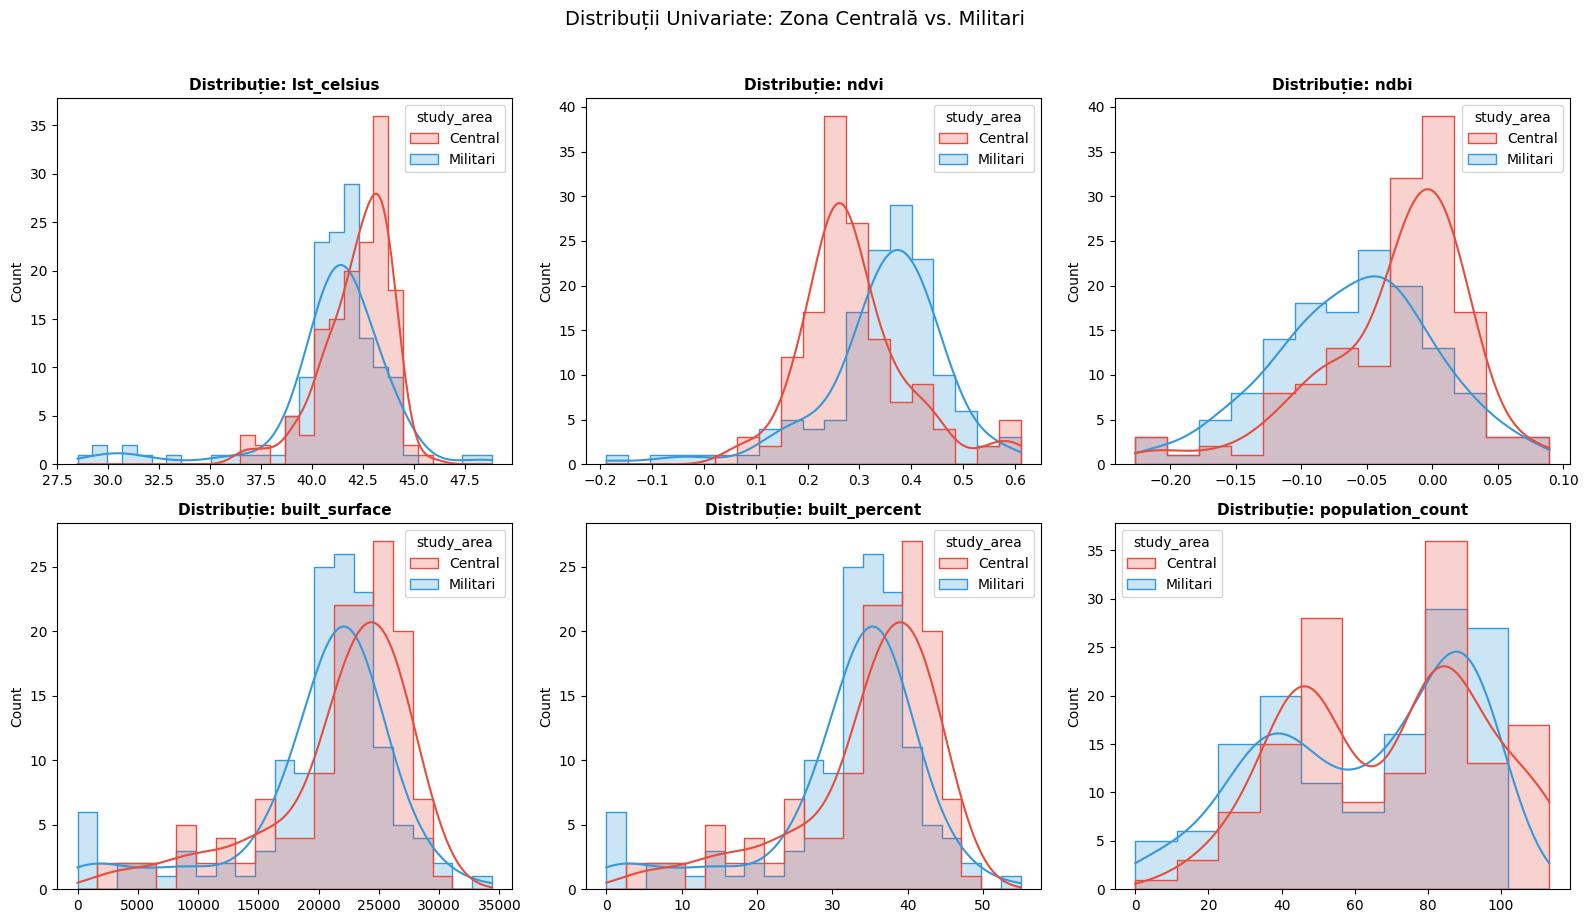

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistici descriptive agregate per zonă
stats_comparison = df_clean_study.groupby('study_area')[feature_cols].agg(
    ['mean', 'std', 'min', 'median', 'max', lambda x: x.skew()]
).round(2)

# Redenumim funcția anonimă pentru claritate
stats_comparison = stats_comparison.rename(columns={'<lambda_0>': 'skewness'})

print("--- STATISTICI DESCRIPTIVE COMPARATIVE ---")
display(stats_comparison)

# 2. Histograme comparative pe fiecare trăsătură
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.histplot(
        data=df_clean_study, 
        x=col, 
        hue='study_area', 
        kde=True, 
        element="step",
        palette={'Central': '#e74c3c', 'Militari': '#3498db'},
        ax=axes[i]
    )
    axes[i].set_title(f"Distribuție: {col}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("")

plt.suptitle("Distribuții Univariate: Zona Centrală vs. Militari", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

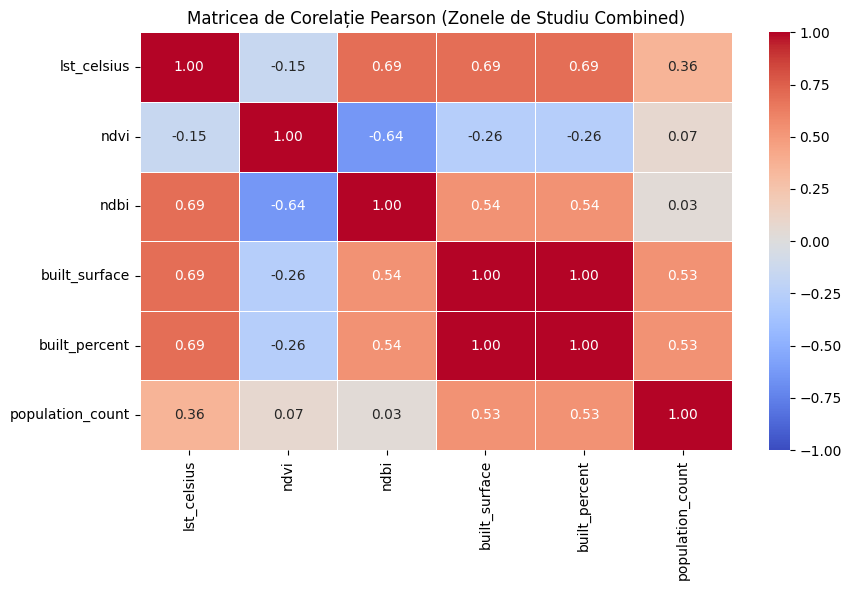

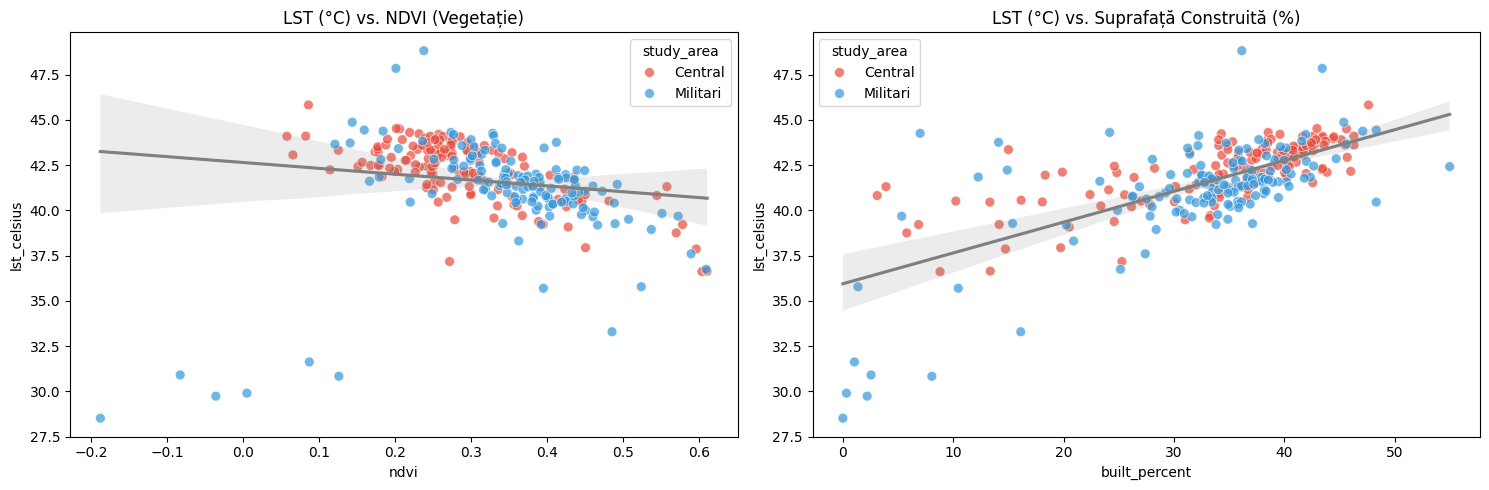

In [44]:
# 1. Heatmap Matrice de Corelație pe întregul eșantion selectat
plt.figure(figsize=(9, 6))
corr_study = df_clean_study[feature_cols].corr()

sns.heatmap(corr_study, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matricea de Corelație Pearson (Zonele de Studiu Combined)", fontsize=12)
plt.tight_layout()
plt.show()

# 2. Scatter Plots Bivariate: LST vs. NDVI & LST vs. Built Percent
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Scatter 1: LST vs. NDVI (Efectul de Răcire)
sns.scatterplot(
    data=df_clean_study, x='ndvi', y='lst_celsius', 
    hue='study_area', palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.7, s=50, ax=ax1
)
sns.regline = sns.regplot(data=df_clean_study, x='ndvi', y='lst_celsius', scatter=False, ax=ax1, color='gray')
ax1.set_title("LST (°C) vs. NDVI (Vegetație)")

# Scatter 2: LST vs. Built Percent (Efectul de Încălzire Minerală)
sns.scatterplot(
    data=df_clean_study, x='built_percent', y='lst_celsius', 
    hue='study_area', palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.7, s=50, ax=ax2
)
sns.regplot(data=df_clean_study, x='built_percent', y='lst_celsius', scatter=False, ax=ax2, color='gray')
ax2.set_title("LST (°C) vs. Suprafață Construită (%)")

plt.tight_layout()
plt.show()

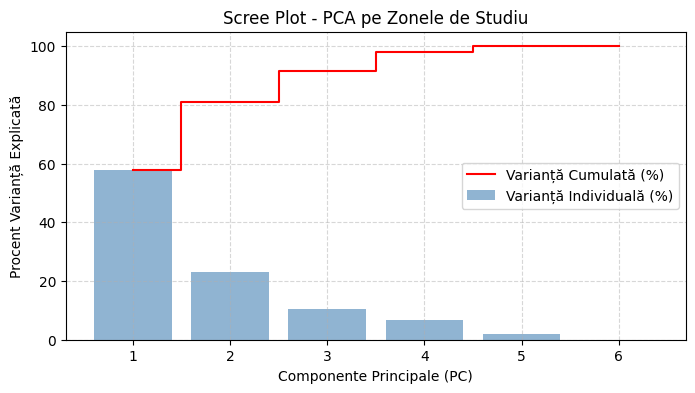

--- MATRICEA LOADINGS ---


,PC1,PC2,PC3,PC4,PC5,PC6
lst_celsius,0.448564,0.030496,0.579381,0.365162,-0.573440,-1.486482e-15
ndvi,-0.231306,0.635153,0.606291,-0.087548,0.409665,7.083959e-16
ndbi,0.406557,-0.472547,0.220966,0.281330,0.695297,1.690598e-15
built_surface,0.501083,0.168225,-0.073483,-0.462812,0.031951,7.071068e-01
built_percent,0.501083,0.168225,-0.073483,-0.462812,0.031951,-7.071068e-01
population_count,0.278980,0.561917,-0.486932,0.592836,0.133647,4.302823e-16


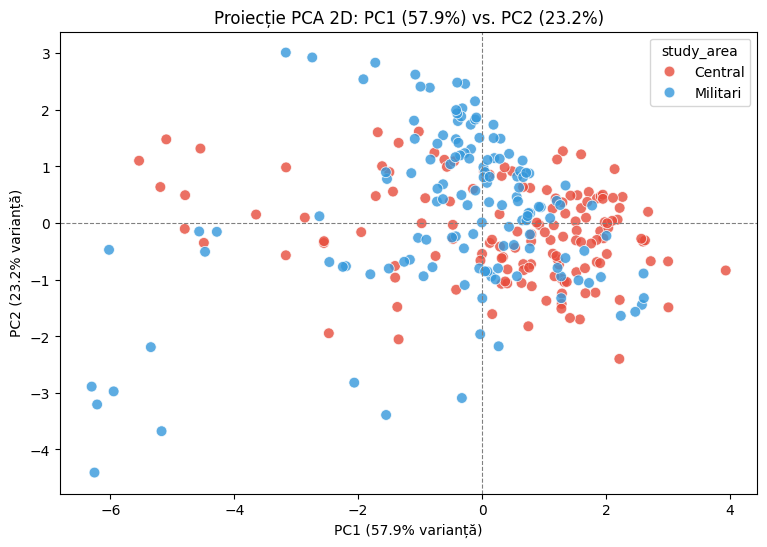

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Standardizarea datelor (Media=0, Varianța=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean_study[feature_cols])

# 2. Aplicarea PCA
pca = PCA(n_components=len(feature_cols))
X_pca = pca.fit_transform(X_scaled)

# Adăugăm primele două componente principale în DataFrame
df_clean_study['PC1'] = X_pca[:, 0]
df_clean_study['PC2'] = X_pca[:, 1]

# 3. Scree Plot (Varianța Explicată)
var_exp = pca.explained_variance_ratio_ * 100
cum_var_exp = np.cumsum(var_exp)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(feature_cols) + 1), var_exp, alpha=0.6, color='steelblue', label='Varianță Individuală (%)')
plt.step(range(1, len(feature_cols) + 1), cum_var_exp, where='mid', color='red', label='Varianță Cumulată (%)')
plt.ylabel('Procent Varianță Explicată')
plt.xlabel('Componente Principale (PC)')
plt.xticks(range(1, len(feature_cols) + 1))
plt.title('Scree Plot - PCA pe Zonele de Studiu')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 4. Matricea Loadings (Contribuția variabilelor în PC1 și PC2)
loadings = pd.DataFrame(
    pca.components_.T, 
    columns=[f'PC{i+1}' for i in range(len(feature_cols))],
    index=feature_cols
)

print("--- MATRICEA LOADINGS ---")
display(loadings)

# 5. Biplot / Scatter 2D: PC1 vs PC2 colorat după zona de studiu
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_clean_study, x='PC1', y='PC2', 
    hue='study_area', palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.8, s=60
)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.title(f"Proiecție PCA 2D: PC1 ({var_exp[0]:.1f}%) vs. PC2 ({var_exp[1]:.1f}%)")
plt.xlabel(f"PC1 ({var_exp[0]:.1f}% varianță)")
plt.ylabel(f"PC2 ({var_exp[1]:.1f}% varianță)")
plt.show()

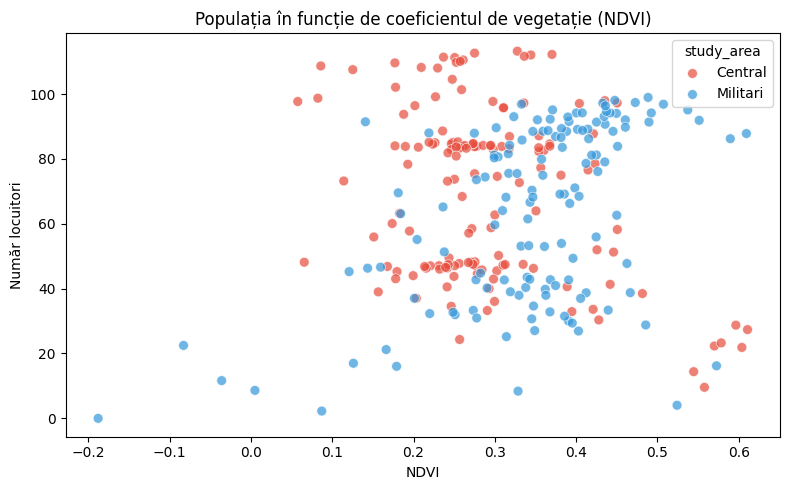

In [46]:
# Populație în funcție de NDVI
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=df_clean_study,
    x='ndvi',
    y='population_count',
    hue='study_area',
    palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.7,
    s=50,
    ax=ax
)

# sns.regplot(
#     data=df_clean_study,
#     x='ndvi',
#     y='population_count',
#     scatter=False,
#     color='gray',
#     ax=ax
# )

ax.set_title("Populația în funcție de coeficientul de vegetație (NDVI)")
ax.set_xlabel("NDVI")
ax.set_ylabel("Număr locuitori")

plt.tight_layout()
plt.show()

In [30]:
df_clean_study

,cell_id,time_window,zone_label,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count,geometry,study_area,lst_interpolated,PC1,PC2
0,cell_03903,2025_summer,Nucleu_Urban_Central,40.322809,0.356555,-0.069063,17378.996078,27.806394,77.277099,"POLYGON ((586145.486 325423.984, 586395.486 32...",Central,False,-1.024526,0.482278
1,cell_03904,2025_summer,Nucleu_Urban_Central,37.172287,0.271738,-0.014667,15798.776471,25.278042,58.507229,"POLYGON ((586145.486 325673.984, 586395.486 32...",Central,False,-1.440219,-0.910722
2,cell_03905,2025_summer,Nucleu_Urban_Central,40.203638,0.425671,-0.100794,16340.960784,26.145537,51.981755,"POLYGON ((586145.486 325923.984, 586395.486 32...",Central,False,-1.802968,0.414754
3,cell_03906,2025_summer,Nucleu_Urban_Central,40.940320,0.300025,-0.018115,21332.384314,34.131815,62.730931,"POLYGON ((586145.486 326173.984, 586395.486 32...",Central,False,0.067062,-0.274151
4,cell_03907,2025_summer,Nucleu_Urban_Central,39.479348,0.278528,0.008528,19380.411765,31.008659,44.606966,"POLYGON ((586145.486 326423.984, 586395.486 32...",Central,False,-0.431489,-1.132418
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
303,cell_02329,2025_summer,Periferie_Periurban,30.901940,-0.082925,-0.121154,1595.545098,2.552872,22.492675,"POLYGON ((582145.486 327923.984, 582395.486 32...",Militari,False,-5.051486,-3.674724
304,cell_02330,2025_summer,Periferie_Periurban,28.511487,-0.187994,-0.176948,0.000000,0.000000,0.000000,"POLYGON ((582145.486 328173.984, 582395.486 32...",Militari,False,-6.069470,-4.438036
305,cell_02419,2025_summer,Periferie_Periurban,40.807452,0.327318,-0.078512,20638.988235,33.022381,75.487372,"POLYGON ((582395.486 325673.984, 582645.486 32...",Militari,False,-0.431969,0.562840
306,cell_02420,2025_summer,Periferie_Periurban,43.660736,0.120768,0.027616,28504.278431,45.606845,45.244972,"POLYGON ((582395.486 325923.984, 582645.486 32...",Militari,False,2.269968,-1.467982


## Comparatie GHS-BUILT-S 2020 și 2025 (OPTIONAL)

In [20]:
import ee
import pandas as pd
import json

ee.Initialize(project='earth-engine-uhi')

# 1. Încărcăm imaginile GHSL pentru cei doi ani
ghsl_2020 = (
    ee.Image('JRC/GHSL/P2023A/GHS_BUILT_S/2020')
    .select('built_surface')
)

ghsl_2025 = (
    ee.Image('JRC/GHSL/P2023A/GHS_BUILT_S/2025')
    .select('built_surface')
)

# 2. Pregătim grila
batch_size = 500
records = []
total_cells = len(gdf_grid_wgs84)

# 3. Extragem valorile pentru fiecare celulă
for i in range(0, total_cells, batch_size):

    batch_gdf = gdf_grid_wgs84.iloc[i:i + batch_size]

    geojson_features = json.loads(
        batch_gdf[['cell_id', 'geometry']].to_json()
    )['features']

    ee_fc = ee.FeatureCollection(geojson_features)

    # GHSL 2020
    reduced_2020 = ghsl_2020.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.mean(),
        scale=100
    )

    # GHSL 2025
    reduced_2025 = ghsl_2025.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.mean(),
        scale=100
    )

    feats_2020 = reduced_2020.getInfo()['features']
    feats_2025 = reduced_2025.getInfo()['features']

    # Asociem valorile după cell_id
    values_2020 = {
        f['properties']['cell_id']: f['properties'].get('mean')
        for f in feats_2020
    }

    values_2025 = {
        f['properties']['cell_id']: f['properties'].get('mean')
        for f in feats_2025
    }

    for cell_id in batch_gdf['cell_id']:

        value_2020 = values_2020.get(cell_id)
        value_2025 = values_2025.get(cell_id)

        records.append({
            'cell_id': cell_id,
            'built_2020': value_2020,
            'built_2025': value_2025
        })

    print(
        f'Progres: {min(i + batch_size, total_cells)} '
        f'/ {total_cells} celule'
    )

# 4. Construim DataFrame-ul
df_ghsl_comparison = pd.DataFrame(records)

# 5. Calculăm diferența absolută și procentuală
df_ghsl_comparison['difference'] = (
    df_ghsl_comparison['built_2025']
    - df_ghsl_comparison['built_2020']
)

df_ghsl_comparison['difference_percent'] = (
    df_ghsl_comparison['difference']
    / df_ghsl_comparison['built_2020'].replace(0, float('nan'))
) * 100

display(df_ghsl_comparison.head())

print('\\nStatistici GHSL 2020:')
print(df_ghsl_comparison['built_2020'].describe())

print('\\nStatistici GHSL 2025:')
print(df_ghsl_comparison['built_2025'].describe())

print('\\nStatistici diferențe:')
print(df_ghsl_comparison['difference'].describe())

Progres: 500 / 9009 celule
Progres: 1000 / 9009 celule
Progres: 1500 / 9009 celule
Progres: 2000 / 9009 celule
Progres: 2500 / 9009 celule
Progres: 3000 / 9009 celule
Progres: 3500 / 9009 celule
Progres: 4000 / 9009 celule
Progres: 4500 / 9009 celule
Progres: 5000 / 9009 celule
Progres: 5500 / 9009 celule
Progres: 6000 / 9009 celule
Progres: 6500 / 9009 celule
Progres: 7000 / 9009 celule
Progres: 7500 / 9009 celule
Progres: 8000 / 9009 celule
Progres: 8500 / 9009 celule
Progres: 9000 / 9009 celule
Progres: 9009 / 9009 celule


,cell_id,built_2020,built_2025,difference,difference_percent
0,cell_00000,452.729064,452.729064,0.000000,0.000000
1,cell_00001,402.214736,402.214736,0.000000,0.000000
2,cell_00002,85.190869,85.190869,0.000000,0.000000
3,cell_00003,23.494154,23.494154,0.000000,0.000000
4,cell_00004,184.980570,202.290803,17.310233,9.357866


\nStatistici GHSL 2020:
count    9009.000000
mean     1648.162884
std      1581.163879
min         0.000000
25%        41.188013
50%      1264.627184
75%      3117.630273
max      9770.273567
Name: built_2020, dtype: float64
\nStatistici GHSL 2025:
count    9009.000000
mean     1687.996439
std      1571.456814
min         0.000000
25%        72.703567
50%      1364.602833
75%      3135.462346
max      9770.273567
Name: built_2025, dtype: float64
\nStatistici diferențe:
count    9.009000e+03
mean     3.983356e+01
std      1.403459e+02
min     -4.547474e-13
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.629173e+03
Name: difference, dtype: float64


# CP2

In [21]:
import pandas as pd
import geopandas as gpd
import numpy as np

# 1. Îmbinăm datele raster și cele morfologice pe baza cell_id
df_features = pd.merge(df_raster, df_morpho[['cell_id', 'built_surface', 'built_percent']], on='cell_id', how='inner')

# 2. Adăugăm zonele administrative / de încadrare (dacă există în gridul tău inițial)
if 'zone_label' in gdf_grid_wgs84.columns:
    df_features = pd.merge(df_features, gdf_grid_wgs84[['cell_id', 'zone_label']], on='cell_id', how='left')
else:
    df_features['zone_label'] = 'Bucuresti_Urban'

# 3. Adăugăm fereastra de timp
df_features['time_window'] = 'Vara_2025'

# 4. Tratăm golurile de date (Imputare logică)
# Pentru populație și suprafață construită, NaN înseamnă absența fenomenului (0)
df_features['population_count'] = df_features['population_count'].fillna(0)
df_features['built_surface'] = df_features['built_surface'].fillna(0)
df_features['built_percent'] = df_features['built_percent'].fillna(0)

# Curățăm eventualele celule unde satelitul a avut doar nori/mască pe LST, NDVI, NDBI
df_clean = df_features.dropna(subset=['lst_celsius', 'ndvi', 'ndbi']).copy()

# Îmbinăm cu geometria pentru a obține GeoDataFrame-ul final
gdf_clean = gdf_grid_wgs84[['cell_id', 'geometry']].merge(df_clean, on='cell_id', how='inner')

print(f"Matricea unificată conține {df_clean.shape[0]} rânduri și {df_clean.shape[1]} coloane.")
display(df_clean.head())

Matricea unificată conține 8567 rânduri și 9 coloane.


,cell_id,lst_celsius,ndvi,ndbi,population_count,built_surface,built_percent,zone_label,time_window
0,cell_00000,36.164025,0.625023,-0.106708,1.998816,2883.262745,4.613220,Periferie_Periurban,Vara_2025
1,cell_00001,38.474571,0.556102,-0.052520,1.502125,2504.772549,4.007636,Periferie_Periurban,Vara_2025
2,cell_00002,43.109277,0.416865,0.005692,0.600958,526.847059,0.842955,Periferie_Periurban,Vara_2025
3,cell_00003,46.424002,0.269983,0.074986,0.116983,149.717647,0.239548,Periferie_Periurban,Vara_2025
4,cell_00004,46.108377,0.261622,0.088478,0.739933,1224.850980,1.959762,Periferie_Periurban,Vara_2025


In [22]:
# Definirea coloanelor numerice d
feature_cols = ['lst_celsius', 'ndvi', 'ndbi', 'built_surface', 'built_percent', 'population_count']

# Metadata pentru raport
metadata_matrix = pd.DataFrame({
    'Trăsătură (Feature)': ['lst_celsius', 'ndvi', 'ndbi', 'built_surface', 'built_percent', 'population_count'],
    'Sursă Date': ['Landsat 8/9 TIRS', 'Sentinel-2 SR', 'Sentinel-2 SR', 'GHSL (JRC)', 'GHSL (JRC)', 'WorldPop 2025'],
    'Metodă Agregare (250m)': ['Medie spațială', 'Medie spațială', 'Medie spațială', 'Medie spațială', 'Calcul procentual', 'Sumă spațială'],
    'Unitate Măsură': ['°C', 'Indice [-1, 1]', 'Indice [-1, 1]', 'm²', '%', 'Locuitori']
})

print("--- METADATA MATRICE X (n x d) ---")
display(metadata_matrix)

--- METADATA MATRICE X (n x d) ---


,Trăsătură (Feature),Sursă Date,Metodă Agregare (250m),Unitate Măsură
0,lst_celsius,Landsat 8/9 TIRS,Medie spațială,°C
1,ndvi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
2,ndbi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
3,built_surface,GHSL (JRC),Medie spațială,m²
4,built_percent,GHSL (JRC),Calcul procentual,%
5,population_count,WorldPop 2025,Sumă spațială,Locuitori


--- STATISTICI DESCRIPTIVE UNIVARIATE ---


,mean,std,min,50%,max,skewness,kurtosis
lst_celsius,41.316234,3.434458,28.474486,41.704219,51.077280,-0.793540,1.040214
ndvi,0.381542,0.161270,-0.262179,0.363090,0.875307,0.567844,0.906322
ndbi,-0.044272,0.103092,-0.440676,-0.027013,0.253735,-0.873997,0.705715
built_surface,10499.549356,9821.743478,0.000000,8407.815686,62184.917647,0.510456,-0.750107
built_percent,16.799279,15.714790,0.000000,13.452505,99.495868,0.510456,-0.750107
population_count,22.688837,29.744058,0.000000,7.723131,115.516189,1.330728,0.563780


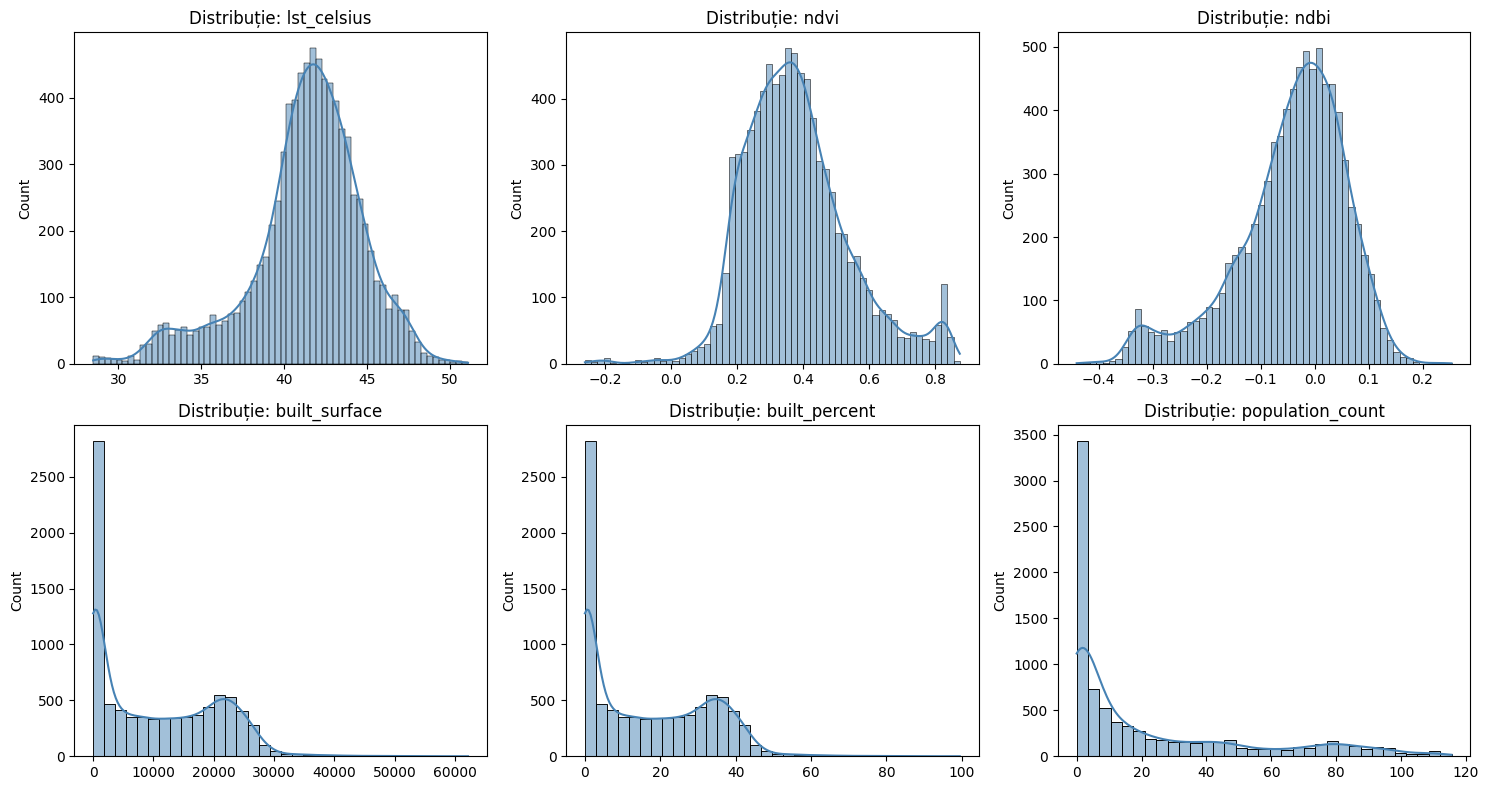

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistici descriptive extinse
stats_df = df_clean[feature_cols].describe().T
stats_df['skewness'] = df_clean[feature_cols].skew()
stats_df['kurtosis'] = df_clean[feature_cols].kurt()

print("--- STATISTICI DESCRIPTIVE UNIVARIATE ---")
display(stats_df[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']])

# 2. Histograme + KDE pentru identificarea asimetriilor
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"Distribuție: {col}")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

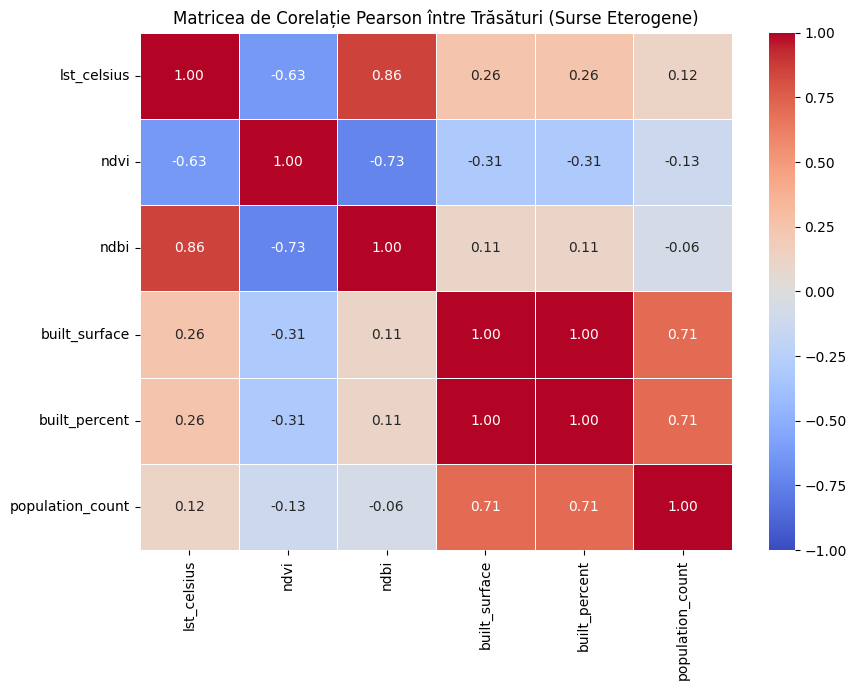

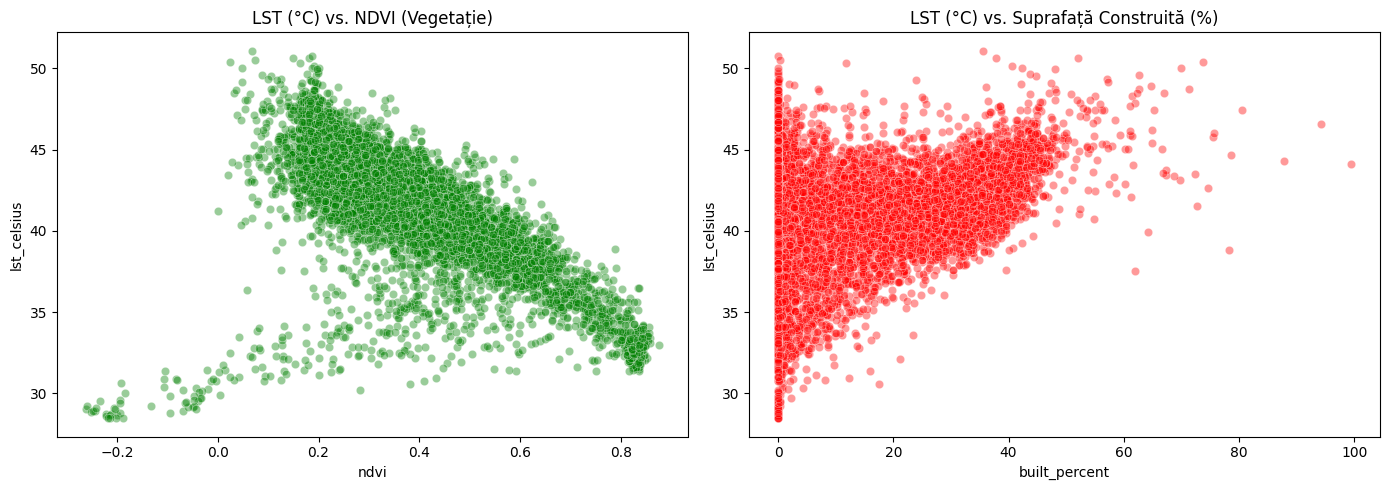

In [24]:
# 1. Calculul matricei de corelație Pearson
corr_matrix = df_clean[feature_cols].corr()

# 2. Plotting Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matricea de Corelație Pearson între Trăsături (Surse Eterogene)")
plt.tight_layout()
plt.show()

# 3. Scatter plot cheie: LST vs. NDVI și LST vs. Built Percent
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_clean, x='ndvi', y='lst_celsius', alpha=0.4, color='green', ax=ax1)
ax1.set_title("LST (°C) vs. NDVI (Vegetație)")

sns.scatterplot(data=df_clean, x='built_percent', y='lst_celsius', alpha=0.4, color='red', ax=ax2)
ax2.set_title("LST (°C) vs. Suprafață Construită (%)")

plt.tight_layout()
plt.show()